In [1]:
"""
ME 144/244: Modeling, Simulation, and Digital Twins of Drone-Based Systems 
Project 5: Optimization of Advanced Materials for Drones
Fall 2026 Semester

STUDENT VERSION
"""
import numpy as np
import matplotlib.pyplot as plt
import pickle

plt.rcParams['animation.embed_limit'] = 2**128


# Step 0

In [3]:
## Given Genetic Algorithm Parameters
P = 10  # number of design strings to breed
K = 10  # number of offspring design strings 
G = 5000  # maximum number of generations
S = 200  # total number of design strings per generation
dv = 5 # number of design variables per string

## Given Properties for Material 1
k1 = 90*10**9         # Phase 1 bulk modulus, [Pa]
mu1 = 20*10**9        # Phase 1 shear modulus, [Pa]
sig1E = 1.1*10**7       # Phase 1 electrical conductivity, [S/m]
K1 = 4.5          # Phase 1 thermal conductivity, [W/m/K]
k_effD = 125*10**9    # Desired effective bulk modulus, [Pa]
mu_effD = 50*10**9    # Desired effective shear modulus, [Pa]
sigE_effD = 2.2*10**7   # Desired effective electrical conductivity,[S/m]
K_effD = 7.5      # Desired effective thermal conductivity, [W/m/K]
TOL_k = 0.5       # Bulk modulus tolerance, []
TOL_mu = 0.5      # Shear modulus tolerance, []
TOL_K = 0.5       # Thermal tolerance, []
TOL_sig = 0.8     # Electrical tolerance, []

## Given Search Bounds for Phase 2 Material
k2min = k1           # Lower bound for Phase 2 bulk modulus, [Pa]
k2max = 10*k1        # Upper bound for bulk modulus, [Pa]
mu2min = mu1         # Lower bound for shear modulus, [Pa]
mu2max = 10*mu1      # Upper bound for shear modulus, [Pa]
K2min = K1           # Lower bound for thermal conductivity, [W/m/K]
K2max = 10*K1        # Upper bound for thermal conductivity, [W/m/K]
sig2Emin = sig1E     # Lower bound for electrical conductivity, [S/m]
sig2Emax = 10*sig1E  # Upper bound for electrical conductivity, [S/m]
v2min = 0            # Lower bound for volume fraction, [fraction]
v2max = 2/3            # Upper bound for volume fraction, [fraction]

## Given Cost Function Weights
W1 = 1/3         # Electrical weight, []
W2 = 1/3          # Thermal weight, []
W3 = 1/3          # Mechanical weight, []
w1 = 1          # Material property cost function weights, []
wj = 0.5          # Concentration tensor weights, []
gamma = 0.5       # Hashin-Shtrikman averaging constant, []

In [4]:
## Genetic Algorithm Helper Functions

def sort(pi):
    new_pi = np.sort(pi, axis=0)
    ind = np.argsort(pi, axis=0)
    return [new_pi, ind]

def reorder(Lambda, ind):
    temp = np.zeros((S,dv))
    for i in range(0, len(ind)):
        temp[i,:] = Lambda[int(ind[i]),:]
    Lambda = temp
    return Lambda

def get_unique_designs(Lambda, new_cost):
    
    # Obtain Unique Strings and Costs
    [unique_costs, iorig, iuniq] = np.unique(new_cost)
    unique_mask = iuniq > 1
    unique_costs = new_cost[:, unique_mask]
    unique_strings = Lambda[:, unique_mask]

    # Mask excludes the first unique value, correct here
    unique_strings = [Lambda[:,1], unique_strings]
    unique_costs = [new_cost[:,1], unique_costs]

    return [unique_strings, unique_costs] 


# Steps 1-6

In [5]:
## Cost Function Definition
# An anonymous function for evaluating fitness
def Pi(Lambda):

    ######## Step 1 ################
    # Extract design parameters from genetic string
    k2 = Lambda[0]    # Phase 2 bulk modulus, [Pa]
    mu2 = Lambda[1]   # Phase 2 shear modulus, [Pa]
    sig2E = Lambda[2] # Phase 2 electrical conductivity, [S/m]
    K2 = Lambda[3]   # Phase 2 thermal conductivity, [W/m/K]
    v2 = Lambda[4]    # Phase 2 volume fraction, []
    v1 = 1 - Lambda[4]    # Phase 1 volume fraction, []
    ################################    

    ######## Step 2 ################
    ## Min and Max Effective Property Bounds
    # Bounds on electrical conductivity
    sigE_min = sig1E + v2 / (1/(sig2E-sig1E) + (1-v2)/(3*sig1E))
    sigE_max = sig2E + (1-v2) / (1/(sig1E-sig2E) + v2/(3*sig2E))
    
    # Bounds on thermal conductivity
    K_min = K1 + v2 / (1/(K2-K1) + (1-v2)/(3*K1)) 
    K_max = K2 + (1-v2) / (1/(K1-K2) + v2/(3*K2))
    
    # Bounds on bulk modulus
    k_min = k1 + v2 / (1/(k2-k1) + 3*(1-v2)/(3*k1 + 4*mu1))
    k_max = k2 + (1-v2) / (1/(k1-k2) + 3*v2/(3*k2 + 4*mu2)) 
    
    # Bounds on shear modulus
    mu_min = mu1 + v2 / (1/(mu2-mu1) + 6*(1-v2)*(k1+2*mu1)/(5*mu1*(3*k1+4*mu1)))
    mu_max = mu2 + (1-v2) / (1/(mu1-mu2) + 6*v2*(k2+2*mu2)/(5*mu2*(3*k2+4*mu2)))
    ################################

    ######## Step 3 ################
    ## Effective Material Properties
    sigE_eff = gamma * (sigE_min + sigE_max)
    K_eff    = gamma * (K_min + K_max)
    k_eff    = gamma * (k_min + k_max)
    mu_eff   = gamma * (mu_min + mu_max)
    ################################

    ######## Step 4 ################
    ## Concentration Tensor Determination
    # Electrical Load Sharing
    CJ1CE1 = (sig1E / sigE_eff) * ((1 / (1-v2)) * (sig2E-sigE_eff) / (sig2E-sig1E))**2
    CJ2CE2 = (sig2E / sigE_eff) * ((1 / v2) * (sigE_eff-sig1E) / (sig2E-sig1E))**2
    
    # Thermal Load Sharing
    Ct2 = (1 / v2) * (K2 - K1)**-1 * (K_eff - K1)
    Ct1 = (1 / v1) * (1 - v2*Ct2)
    Cq2 = K2 * Ct2 * K_eff**-1
    Cq1 = (1 - v2 * Cq2) / (1 - v2)
        
    # Mechanical Load Sharing
    Ck2  = (1 / v2) * (k2 / k_eff) * ((k_eff - k1) / (k2 - k1))
    Cmu2 = (1 / v2) * (mu2 / mu_eff) * ((mu_eff - mu1) / (mu2 - mu1))
    Ck1  = (1 / v1) * (1 - v2 * Ck2)
    Cmu1 = (1 / v1) * (1 - v2 * Cmu2)
    ################################

    ## Cost Function Weight Determination
    # Assign concentration tensor weights
    w2E = wj
    w3E = wj
    w2T = wj
    w3T = wj
    w3M = wj
    w4M = wj
    w5M = wj
    w6M = wj
    
    ######## Step 5 ################
    # Electrical weights
    if (CJ1CE1 - TOL_sig) / (TOL_sig) > 0:
        w2E_hat = w2E
    else:
        w2E_hat = 0

    if (CJ2CE2 - TOL_sig) / (TOL_sig) > 0:
        w3E_hat = w3E
    else:
        w3E_hat = 0
    
    # Thermal weights
    if (Cq1 - TOL_K) / (TOL_K) > 0:
        w2T_hat = w2T
    else:
        w2T_hat = 0

    if (Cq2 - TOL_K) / (TOL_K) > 0:
        w3T_hat = w3T
    else:
        w3T_hat = 0
    
    # Mechanical weights
    if Ck2 > TOL_k:
        w3M_hat = w3M
    else:
        w3M_hat = 0

    if Cmu2 > TOL_mu:
        w4M_hat = w4M  
    else:
        w4M_hat = 0

    if Ck1 > TOL_k:
        w5M_hat = w5M
    else:
        w5M_hat = 0

    if Cmu1 > TOL_mu:
        w6M_hat = w6M
    else:
        w6M_hat = 0
    ################################

    ######## Step 6 ################
    ## Cost Functions
    # Electrical Property Cost Function
    Pi_elec = w1 * ((sigE_effD - sigE_eff) / sigE_effD)**2 + w2E_hat * ((CJ1CE1 - TOL_sig) / (TOL_sig))**2 + w3E_hat * ((CJ2CE2 - TOL_sig) / (TOL_sig))**2

    # Thermal Property Cost Function    
    Pi_thermo = w1 * ((K_effD - K_eff) / K_effD)**2 + w2T_hat * ((Cq1 - TOL_K) / (TOL_K))**2 + w3T_hat * ((Cq2 - TOL_K) / (TOL_K))**2
        
    # Mechanical Property Cost Function
    Pi_mech = (w1 * ((k_effD - k_eff) / k_effD)**2 
                + w1 * ((mu_effD - mu_eff) / mu_effD)**2 
                + w3M_hat * ((Ck2 - TOL_k) / (TOL_k))**2 
                + w4M_hat * ((Cmu2 - TOL_mu) / (TOL_mu))**2 
                + w5M_hat * ((Ck1 - TOL_k) / (TOL_k))**2 
                + w6M_hat * ((Cmu1 - TOL_mu) / (TOL_mu))**2)

    # Multi-property (Combined) Cost Function
    cost = W1 * Pi_elec + W2 * Pi_thermo + W3 * Pi_mech

    return cost
    ################################

# Question 1 Case A

In [6]:
# - Keep the top P=10 parents after each generation
# - Produce 10 offspring
# - Generate 180 new random strings

def caseA():
    
    # Initialize arrays to store the cost and original indices of each generation
    PI = np.ones((G, S))
    Orig = np.ones((G, S))
    
    # Initialize arrays to store best performer and parent avg 
    Pi_min = np.zeros(G)     # best cost
    Pi_par_avg = np.zeros(G) # avg cost of parents
    
    # Generation counter
    g = 0

    # Initialize array to store costs for current generation
    cost = np.zeros(S)

    # Randomly populate first generation  
    Lambda = np.ones((S, dv))
    for i in range (S):
        k2    = np.random.uniform(k2min, k2max)
        mu2   = np.random.uniform(mu2min, mu2max)
        sig2E = np.random.uniform(sig2Emin, sig2Emax)
        K2    = np.random.uniform(K2min, K2max)
        v2    = np.random.uniform(v2min, v2max)  
            
        # Evaluate initial population
        Lambda[i, :] = k2, mu2, sig2E, K2, v2
        cost[i] = Pi(Lambda[i, :])
            
    # Sort the costs of the first generation
    [new_cost, ind] = sort(cost)  
    PI[g, :] = new_cost.reshape(1,S) 
    
    # Store the cost of the best performer and average cost of the parents 
    Pi_min[g] = np.min(new_cost)
    Pi_par_avg[g] = np.mean(new_cost[0:P])
    
    # Update Lambda based on sorted indices
    Lambda = reorder(Lambda, ind)
    Orig[g,:] = ind.reshape(1,S) 
    
    # Perform all later generations    
    while g < G:
        
        print(g)
        cost[0:P] = new_cost[0:P] # retain the parents from the previous generation
        
        # Select top parents P from Lambda to be breeders
        for p in range(0, P, 2):
            phi1, phi2 = np.random.rand(2)
            kid1 = phi1*Lambda[p, :] + (1-phi1)*Lambda[p+1, :]
            kid2 = phi2*Lambda[p, :] + (1-phi2)*Lambda[p+1, :]
            
            # Append offspring to Lambda 
            Lambda[P+p,   :] = kid1
            Lambda[P+p+1, :] = kid2
        
            # Evaluate Offspring
            cost[P+p]   = Pi(Lambda[P+p, :])
            cost[P+p+1] = Pi(Lambda[P+p+1, :])
                     
        # Randomly generate new design strings to fill the rest of the population
        for i in range(S-P-K):
            k2    = np.random.uniform(k2min, k2max)
            mu2   = np.random.uniform(mu2min, mu2max)
            sig2E = np.random.uniform(sig2Emin, sig2Emax)
            K2    = np.random.uniform(K2min, K2max)
            v2    = np.random.uniform(v2min, v2max)  
            
            # Evaluate population
            Lambda[P+K+i, :] = k2, mu2, sig2E, K2, v2
            cost[P+K+i] = Pi(Lambda[P+K+i, :])

        # Sort the costs for the gth generation
        [new_cost, ind] = sort(cost)  
        PI[g, :] = new_cost.reshape(1,S) 
    
        # Store the cost of the best performer and average cost of the parents 
        Pi_min[g] = np.min(new_cost)
        Pi_par_avg[g] = np.mean(new_cost[0:P])
    
        # Update Lambda based on sorted indices
        Lambda = reorder(Lambda, ind)
        Orig[g,:] = ind.reshape(1,S)  

        # Update the generation counter
        g = g + 1          
    
    return PI, Lambda, Orig, Pi_min, Pi_par_avg   


In [49]:
# Call the Genetic Algorithm for Case A  
PI, Lambda, Orig, Pi_min, Pi_par_avg = caseA() # Keep the top P=10 parents after each generation
                                               # Produce 10 offspring
                                               # Generate 180 new random strings

caseA_results = {
    "PI": PI,
    "Lambda": Lambda,
    "Orig": Orig,
    "Pi_min": Pi_min,
    "Pi_par_avg": Pi_par_avg,
}

with open("caseA_results.pkl", "wb") as f:
    pickle.dump(caseA_results, f)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

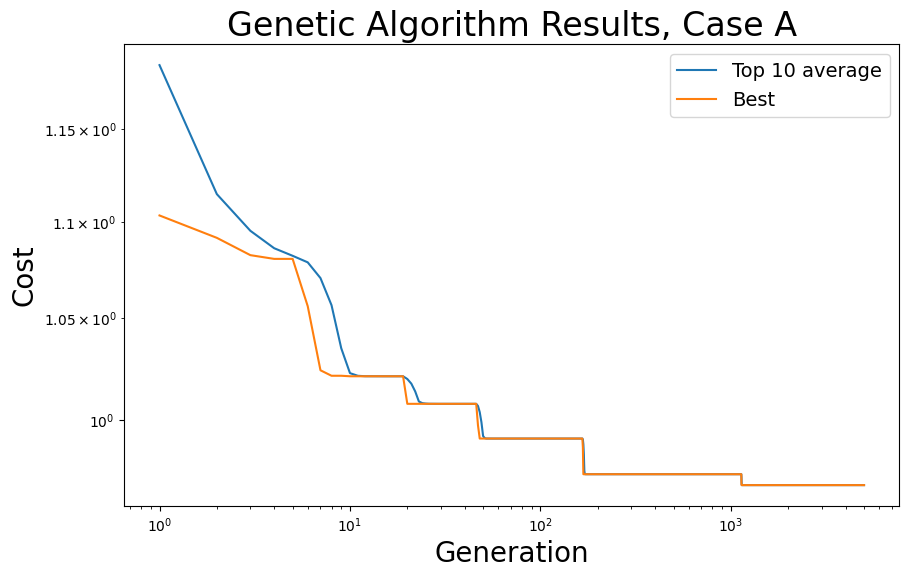

In [56]:
# Plotting
if 'caseA_results' not in globals():
    with open("caseA_results.pkl", "rb") as f:
        caseA_results = pickle.load(f)

PI = caseA_results["PI"]
Lambda = caseA_results["Lambda"]
Orig = caseA_results["Orig"]
Pi_min = caseA_results["Pi_min"]
Pi_par_avg = caseA_results["Pi_par_avg"]
fig, ax = plt.subplots(figsize=(10,6))
generations = np.arange(1, G + 1)
ax.loglog(generations, Pi_par_avg, label='Top 10 average')
ax.loglog(generations, Pi_min, label='Best')
plt.xlabel('Generation', fontsize= 20)
plt.ylabel('Cost', fontsize=20)
plt.title('Genetic Algorithm Results, Case A', fontsize = 24)
plt.legend(fontsize = 14)
plt.show()

# Question 1 Case B

In [70]:
# - Do NOT keep top P=10 parents after each generation
# - Produce 10 offspring
# - Generate 190 new random strings

def caseB():
    
    # Initialize arrays to store the cost and original indices of each generation
    PI = np.ones((G, S))
    Orig = np.ones((G, S))
    
    # Initialize arrays to store best performer and parent avg 
    Pi_min = np.zeros(G)     # best cost
    Pi_par_avg = np.zeros(G) # avg cost of parents
    
    # Generation counter
    g = 0

    # Initialize array to store costs for current generation
    cost = np.zeros(S)

    # Randomly populate first generation  
    Lambda = np.ones((S, dv))
    for i in range (S):
        k2    = np.random.uniform(k2min, k2max)
        mu2   = np.random.uniform(mu2min, mu2max)
        sig2E = np.random.uniform(sig2Emin, sig2Emax)
        K2    = np.random.uniform(K2min, K2max)
        v2    = np.random.uniform(v2min, v2max)  
            
        # Evaluate initial population
        Lambda[i, :] = k2, mu2, sig2E, K2, v2
        cost[i] = Pi(Lambda[i, :])
            
    # Sort the costs of the first generation
    [new_cost, ind] = sort(cost)  
    PI[g, :] = new_cost.reshape(1,S) 
    
    # Store the cost of the best performer and average cost of the parents 
    Pi_min[g] = np.min(new_cost)
    Pi_par_avg[g] = np.mean(new_cost[0:P])
    
    # Update Lambda based on sorted indices
    Lambda = reorder(Lambda, ind)
    Orig[g,:] = ind.reshape(1,S) 
    g += 1
     
    # Perform all later generations    
    while g < G:
        
        print(g)

        ######## Step 7 ################
        # cost = 0 # Not storing parents from the previous generationv
        
        # Select top parents P from Lambda to be breeders
        for p in range(0, P, 2):
            phi1, phi2 = np.random.rand(2)
            kid1 = phi1*Lambda[p, :] + (1-phi1)*Lambda[p+1, :]
            kid2 = phi2*Lambda[p, :] + (1-phi2)*Lambda[p+1, :]
            
            # Append offspring to Lambda (children fill in spots where parents would be)
            Lambda[p,   :] = kid1
            Lambda[p+1, :] = kid2
        
            # Evaluate Offspring
            cost[p] = Pi(Lambda[p, :])
            cost[p+1] = Pi(Lambda[p+1, :])
        ################################
              
        # Randomly generate new design strings to fill th rest of the population
        for i in range(S-K):
            k2    = np.random.uniform(k2min, k2max)
            mu2   = np.random.uniform(mu2min, mu2max)
            sig2E = np.random.uniform(sig2Emin, sig2Emax)
            K2    = np.random.uniform(K2min, K2max)
            v2    = np.random.uniform(v2min, v2max)  
            
            # Evaluate population
            Lambda[K+i, :] = k2, mu2, sig2E, K2, v2
            cost[K+i] = Pi(Lambda[K+i, :])

        # Sort the costs for the gth generation
        [new_cost, ind] = sort(cost)  
        PI[g, :] = new_cost.reshape(1,S) 
    
        # Store the cost of the best performer and average cost of the parents 
        Pi_min[g] = np.min(new_cost)
        Pi_par_avg[g] = np.mean(new_cost[0:P])
    
        # Update Lambda based on sorted indices
        Lambda = reorder(Lambda, ind)
        Orig[g,:] = ind.reshape(1,S)  

        # Update the generation counter
        g = g + 1          
    
    return PI, Lambda, Orig, Pi_min, Pi_par_avg   


In [58]:
# Call the Genetic Algorithm for Case B  
PI, Lambda, Orig, Pi_min, Pi_par_avg = caseB() # Do NOT keep the top P=10 parents after each generation
                                               # Produce 10 offspring
                                               # Generate 190 new random strings

caseB_results = {
    "PI": PI,
    "Lambda": Lambda,
    "Orig": Orig,
    "Pi_min": Pi_min,
    "Pi_par_avg": Pi_par_avg,
}

with open("caseB_results.pkl", "wb") as f:
    pickle.dump(caseB_results, f)

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277


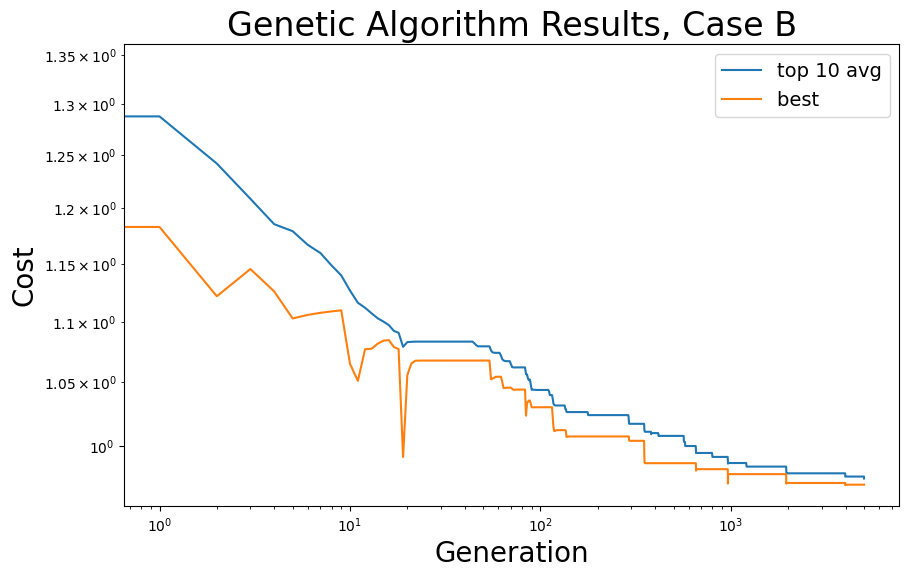

In [59]:
# Plotting
if 'caseB_results' not in globals():
    with open("caseB_results.pkl", "rb") as f:
        caseB_results = pickle.load(f)
        
fig, ax = plt.subplots(figsize=(10,6))
ax.loglog(range(G), Pi_par_avg, label='top 10 avg')
ax.loglog(range(G), Pi_min, label="best ")
plt.xlabel('Generation', fontsize= 20)
plt.ylabel('Cost', fontsize=20)
plt.title('Genetic Algorithm Results, Case B', fontsize = 24)
plt.legend(fontsize = 14)
plt.show()

# Question 1 Case C

In [60]:
# - Keep top P=10 parents after each generation
# - Produce 10 offspring with mutations using random weights [-1/2, 3/2] instead of [0, 1]
# - Generate 180 new random strings

######## Step 8 ################
a = np.random.uniform(-1/2, 3/2, size=(P, dv))
b = np.random.uniform(-1/2, 3/2, size=(P, dv))
################################

def caseC():
    
    # Initialize arrays to store the cost and original indices of each generation
    PI = np.ones((G, S))
    Orig = np.ones((G, S))
    
    # Initialize arrays to store best performer and parent avg 
    Pi_min = np.zeros(G)     # best cost
    Pi_par_avg = np.zeros(G) # avg cost of parents
    
    # Generation counter
    g = 0

    # Initialize array to store costs for current generation
    cost = np.zeros(S)

    # Randomly populate first generation  
    Lambda = np.ones((S, dv))
    for i in range (S):
        k2    = np.random.uniform(k2min, k2max)
        mu2   = np.random.uniform(mu2min, mu2max)
        sig2E = np.random.uniform(sig2Emin, sig2Emax)
        K2    = np.random.uniform(K2min, K2max)
        v2    = np.random.uniform(v2min, v2max)  
            
        # Evaluate initial population
        Lambda[i, :] = k2, mu2, sig2E, K2, v2
        cost[i] = Pi(Lambda[i, :])
            
    # Sort the costs of the first generation
    [new_cost, ind] = sort(cost)  
    PI[g, :] = new_cost.reshape(1,S) 
    
    # Store the cost of the best performer and average cost of the parents 
    Pi_min[g] = np.min(new_cost)
    Pi_par_avg[g] = np.mean(new_cost[0:P])
    
    # Update Lambda based on sorted indices
    Lambda = reorder(Lambda, ind)
    Orig[g,:] = ind.reshape(1,S) 
    
    g += 1
    # Perform all later generations    
    while g < G:
        
        print(g)
        cost[0:P] = new_cost[0:P] # retain the parents from the previous generation
        
        ######## Step 9 ################
        # Select top parents P from Lambda to be breeders
        for p in range(0, P, 2):
            phi1 = a[p, :]
            phi2 = b[p, :]
            kid1 = phi1*Lambda[p, :] + (1-phi1)*Lambda[p+1, :]
            kid2 = phi2*Lambda[p, :] + (1-phi2)*Lambda[p+1, :]
            
            # Append offspring to Lambda 
            Lambda[P+p,   :] = kid1
            Lambda[P+p+1, :] = kid2
        
            # Evaluate Offspring
            cost[P+p]   = Pi(Lambda[P+p, :])
            cost[P+p+1] = Pi(Lambda[P+p+1, :])
        ################################
                 
        # Randomly generate new design strings to fill th rest of the population
        for i in range(S-P-K):
            k2    = np.random.uniform(k2min, k2max)
            mu2   = np.random.uniform(mu2min, mu2max)
            sig2E = np.random.uniform(sig2Emin, sig2Emax)
            K2    = np.random.uniform(K2min, K2max)
            v2    = np.random.uniform(v2min, v2max)  
            
            # Evaluate population
            Lambda[P+K+i, :] = k2, mu2, sig2E, K2, v2
            cost[P+K+i] = Pi(Lambda[P+K+i, :])

        # Sort the costs for the gth generation
        [new_cost, ind] = sort(cost)  
        PI[g, :] = new_cost.reshape(1,S) 
    
        # Store the cost of the best performer and average cost of the parents 
        Pi_min[g] = np.min(new_cost)
        Pi_par_avg[g] = np.mean(new_cost[0:P])
    
        # Update Lambda based on sorted indices
        Lambda = reorder(Lambda, ind)
        Orig[g,:] = ind.reshape(1,S)  

        # Update the generation counter
        g += 1          
    
    return PI, Lambda, Orig, Pi_min, Pi_par_avg   


In [65]:
# Call the Genetic Algorithm for Case C  
PI, Lambda, Orig, Pi_min, Pi_par_avg = caseC() # Keep top P=10 parents after each generation
                                               # Produce 10 offspring with mutations using random weights [-1/2, 3/2] instead of [0, 1]
                                               # Generate 180 new random strings 
                                               

caseC_results = {
    "PI": PI,
    "Lambda": Lambda,
    "Orig": Orig,
    "Pi_min": Pi_min,
    "Pi_par_avg": Pi_par_avg,
}

with open("caseC_results.pkl", "wb") as f:
    pickle.dump(caseC_results, f)

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277


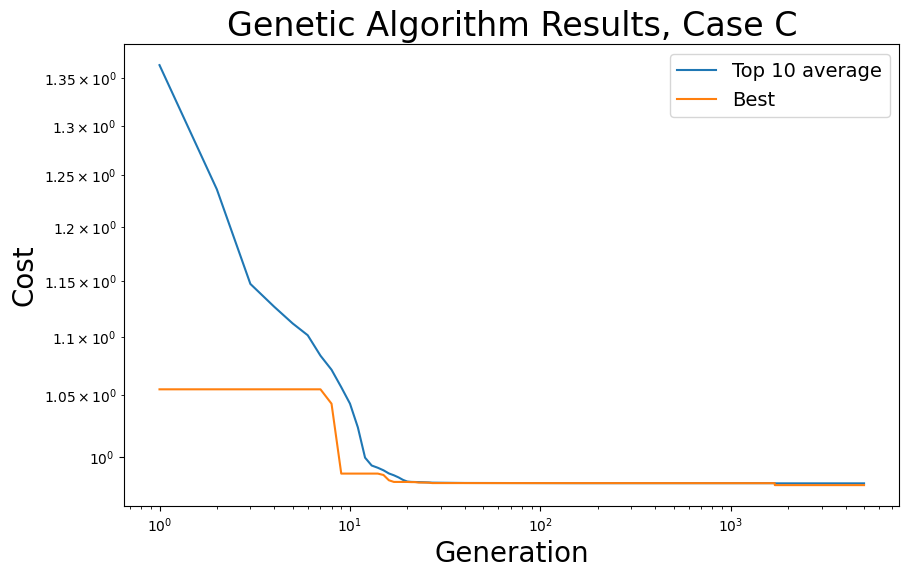

In [66]:
# Plotting
if 'caseC_results' not in globals():
    with open("caseC_results.pkl", "rb") as f:
        caseC_results = pickle.load(f)

fig, ax = plt.subplots(figsize=(10,6))
generations = np.arange(1, G + 1)
ax.loglog(generations, Pi_par_avg, label='Top 10 average')
ax.loglog(generations, Pi_min, label='Best')
plt.xlabel('Generation', fontsize= 20)
plt.ylabel('Cost', fontsize=20)
plt.title('Genetic Algorithm Results, Case C', fontsize = 24)
plt.legend(fontsize = 14)
plt.show()

# Question 3

In [64]:
if 'caseA_results' not in globals():
    with open("caseA_results.pkl", "rb") as f:
        caseA_results = pickle.load(f)
if 'caseB_results' not in globals():
    with open("caseB_results.pkl", "rb") as f:
        caseB_results = pickle.load(f)
if 'caseC_results' not in globals():
    with open("caseC_results.pkl", "rb") as f:
        caseC_results = pickle.load(f)

decimals = 4
print("Top 4 Designs Case A:")
for i in range(4):
    print(f'Lambda[{i}]')
    print(caseA_results['Lambda'][i,:])
    print(f'PI[{i}]')
    print(np.round(caseA_results['PI'][-1,i], decimals))
    print('\n ')

print('\n \n ')

print("Top 4 Designs Case B:")
for i in range(4):
    print(f'Lambda[{i}]')
    print(caseB_results['Lambda'][i,:])
    print(f'PI[{i}]')
    print(np.round(caseB_results['PI'][-1,i], decimals))
    print('\n ')

print('\n \n ')

print("Top 4 Designs Case C:")
for i in range(4):
    print(f'Lambda[{i}]')
    print(caseC_results['Lambda'][i,:])
    print(f'PI[{i}]')
    print(np.round(caseC_results['PI'][-1,i], decimals))
    print('\n ')

Top 4 Designs Case A:
Lambda[0]
[1.82194800e+11 6.53863623e+10 2.88822138e+07 7.25957208e+00
 6.62993138e-01]
PI[0]
0.969

 
Lambda[1]
[1.82194800e+11 6.53863623e+10 2.88822138e+07 7.25957208e+00
 6.62993138e-01]
PI[1]
0.969

 
Lambda[2]
[1.82194800e+11 6.53863623e+10 2.88822138e+07 7.25957208e+00
 6.62993138e-01]
PI[2]
0.969

 
Lambda[3]
[1.82194800e+11 6.53863623e+10 2.88822138e+07 7.25957208e+00
 6.62993138e-01]
PI[3]
0.969

 

 
 
Top 4 Designs Case B:
Lambda[0]
[1.43189645e+11 7.19426596e+10 3.23462067e+07 8.21812899e+00
 6.61509069e-01]
PI[0]
0.9704

 
Lambda[1]
[1.43189645e+11 7.19426596e+10 3.23462067e+07 8.21812899e+00
 6.61509069e-01]
PI[1]
0.9704

 
Lambda[2]
[1.42246914e+11 6.35479400e+10 3.16418909e+07 8.11124612e+00
 6.58669748e-01]
PI[2]
0.9704

 
Lambda[3]
[1.33345982e+11 6.15039247e+10 3.14519796e+07 7.90935693e+00
 6.60082512e-01]
PI[3]
0.9716

 

 
 
Top 4 Designs Case C:
Lambda[0]
[1.64306457e+11 5.97470874e+10 3.05359599e+07 8.35738099e+00
 6.56960299e-01]
PI[0]
0.